# Training the model using CNN

In the previous stage we succesfully inspected the data, checked its quality, and defined the data splits. In the following we will:
* cut every file into 2 second windows to feed into the model
* attach labels to every window (0 or 1)
* Stack them into an array CNN can consume (possibly normalize)
* Define the CNN architecture
* Write the training loop
* Track training vs. validation accuracy/loss per epoch 

In [1]:
import importlib
import numpy as np
import pandas as pd
from helpers import load, window
from constants import FILE_S, WIN_S
import dataset
import torch
from torch.utils.data import TensorDataset, DataLoader

dataset = importlib.reload(dataset)
files = dataset.files
splits = dataset.splits


## Cut every file into windows.
Each ~70 second file gives about 35 non-overlapping 2-second windows.
Windows can have different row counts because packet rate slightly differs between files, however CNN needs a fixed one. Here we pick the window size to be the smallest window length we can find.

In [2]:
def make_windows(files, label, T): #T is the # of rows every window must have
    X, y = [], [] #X will collect the inputs, y will collect the correct labels
    for f in files:
        df = load(f) #reads on csv file into a table and drops the two edge carriers (helper function)
        for start in range(0, FILE_S, WIN_S):
            w = window(df, start) #cuts out the 2-sec window starting from start
            if len(w) >= T: #safety check
                w = w[:T]
                X.append(w - np.median(w, axis=0)) #computes median for each subcarrier (appending the centered data around 0 to X)
                y.append(label)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32) #turns the arrays into numpy arrays, float32 is the type PyTorch expects (also less memory)

'''Finding T - the smallest window length'''
all_files =files["empty"] + files["person"] #one big list
T = min(len(window(load(f), 10)) for f in all_files) #take a 2sec window starting at 10sec from each file by first loading it, then compare the length of that window (some packet rates are faster than other so more rows), then choose min 


## Next step is to build the splits

In [3]:
def build(part):
    Xe, ye = make_windows(splits["empty"][part],  0, T)
    Xp, yp = make_windows(splits["person"][part], 1, T)
    return np.concatenate([Xe, Xp]), np.concatenate([ye, yp])

X_train, y_train = build("train")
X_val,   y_val   = build("val")
X_test,  y_test  = build("test")

for name, X, y in (("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)):
    print(name, X.shape, y.shape, "empty:", int((y == 0).sum()), "person:", int((y == 1).sum()))
pd.DataFrame(X_train[0][:5,:5])

train (1995, 81, 47) (1995,) empty: 210 person: 1785
val (665, 81, 47) (665,) empty: 70 person: 595
test (665, 81, 47) (665,) empty: 70 person: 595


,0,1,2,3,4
0,2.432702,6.327237,-1.950626,1.491439,-5.763897
1,5.234189,4.724953,2.869820,0.488853,0.587975
2,6.750565,14.484240,7.391074,8.373919,3.815616
3,6.743281,5.205689,9.743284,10.189011,11.285751
4,12.209437,8.930522,11.832970,9.308620,11.742233


## Data validity checks
Before training we check that the data is set up correctly:
* **No leakage:** no recording file appears in more than one split (all overlaps should be empty sets).
* **Class imbalance:** the window counts above show about 8.5 person windows for every empty window, so plain accuracy is misleading (always guessing "person" gives 89.5%).
* **Value level per class:** mean of the median-centred windows per class (empty about 5, person about 21). Sanity check 1 tests whether this alone predicts the label.
* **Packet counts per class:** the ranges overlap between classes, so recording length is not a giveaway.
* **Spread per class:** the standard deviations are similar (about 180 vs 152), so overall spread is not an obvious shortcut either.

In [4]:
# sanity check: no file should appear in more than one split
train_files = set(splits["empty"]["train"]) | set(splits["person"]["train"])
val_files   = set(splits["empty"]["val"])   | set(splits["person"]["val"])
test_files  = set(splits["empty"]["test"])  | set(splits["person"]["test"])

print("train & val overlap:", train_files & val_files)
print("train & test overlap:", train_files & test_files)
print("val & test overlap:", val_files & test_files)

# check 1: overall value difference between classes
print("empty windows mean:", X_train[y_train == 0].mean())
print("person windows mean:", X_train[y_train == 1].mean())

# check 2: do file lengths differ systematically between classes?
for name in ("empty", "person"):
    counts = [len(load(f)) for f in files[name]]
    print(name, "packet counts: min", min(counts), "max", max(counts), "mean", sum(counts)/len(counts))

# check 3: spread/variance difference between classes
print("empty windows std:", X_train[y_train == 0].std())
print("person windows std:", X_train[y_train == 1].std())

train & val overlap: set()
train & test overlap: set()
val & test overlap: set()
empty windows mean: 4.969699
person windows mean: 21.339602
empty packet counts: min 4903 max 7249 mean 5764.1
person packet counts: min 2866 max 14874 mean 6095.552941176471
empty windows std: 180.49188
person windows std: 152.04529


In [5]:
# Scale the data using stats only from training set to avoid data leakage
mean = X_train.mean()
std = X_train.std()
print("mean/std from train:", mean, std)

X_train_s = (X_train - mean) / std
X_val_s   = (X_val   - mean) / std
X_test_s  = (X_test  - mean) / std

print("train mean/std after scaling:", X_train_s.mean(), X_train_s.std())
print("The first window limited to the first 5 packets and 5 subcarriers:")
pd.DataFrame(X_train_s[0][:5, :5]) 

mean/std from train: 19.616455 155.3665
train mean/std after scaling: 0.0 1.0
The first window limited to the first 5 packets and 5 subcarriers:


,0,1,2,3,4
0,-0.110601,-0.085535,-0.138814,-0.116660,-0.163358
1,-0.092570,-0.095848,-0.107788,-0.123113,-0.122475
2,-0.082810,-0.033033,-0.078687,-0.072361,-0.101700
3,-0.082857,-0.092753,-0.063548,-0.060679,-0.053620
4,-0.047674,-0.068779,-0.050098,-0.066345,-0.050682


## Add the channel dimension
Reshapes the data from (N, T, 47) to (N, 1, T, 47), adding the "channel" dimension that PyTorch's CNN layers expect

In [6]:
X_train_s = X_train_s[:, None, :, :] #makes shape go from (N,T,47) into (N,1,T,47) None means to insert a new dimension of size 1
X_val_s   = X_val_s[:, None, :, :]
X_test_s  = X_test_s[:, None, :, :]
print("The shape of X_train_s: ", X_train_s.shape)   # should be (N, 1, T, 47), N is the number of windows, 1 is the channel dimension this case just amplitude

The shape of X_train_s:  (1995, 1, 81, 47)


In [7]:
#Converts the NumPy arrays into PyTorch tensors which the data format PyTorch's models and training tools operate on. 
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train,   dtype=torch.float32)

X_val_t = torch.tensor(X_val_s, dtype=torch.float32)
y_val_t = torch.tensor(y_val,   dtype=torch.float32)

X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test,   dtype=torch.float32)

print(X_train_t.shape, X_train_t.dtype)

torch.Size([1995, 1, 81, 47]) torch.float32


# PyTorch's DataLoaders
Wraps the tensors into batches for training: groups windows into batches of 32, shuffles the training data each epoch, and hands out one batch at a time during the training loop.

In [8]:
#1 we pair up our X and y
train_ds = TensorDataset(X_train_t, y_train_t)
val_ds   = TensorDataset(X_val_t,   y_val_t)
test_ds  = TensorDataset(X_test_t,  y_test_t)

#2 wrap each dataset in a DataLoader
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

for X_batch, y_batch in train_loader:
    print(X_batch.shape, y_batch.shape)
    break #look only at first batch for now

torch.Size([32, 1, 81, 47]) torch.Size([32])


## Defining the CNN

In [9]:
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(16,1)
    def forward(self, x):
        x = self.relu(self.conv1(x)) #run thourgh first conv layer and apply relu
        x = self.pool(x) #looks at every non-overlapping 2×2 patch, keeps only the biggest value, discards the rest
        x = self.relu(self.conv2(x)) #run a second layer
        x = self.pool(x) #again
        x = self.global_pool(x) #end up with 16 final values
        x = x.flatten(1) # get rid of the 1,1
        x = self.fc(x) #end up with one prediction or value for the window
        return x.squeeze(1)
model = SimpleCNN()
print(model)


SimpleCNN(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (global_pool): AdaptiveAvgPool2d(output_size=1)
  (fc): Linear(in_features=16, out_features=1, bias=True)
)


## Loss function and optimizer

In [10]:
import torch.optim as optim

n_empty = (y_train == 0).sum() #y_train is the array of labels 1 or 0
n_person = (y_train == 1).sum() # these produce an array of T/F values, one per window

#using tensor so pytorch loss func can use it
pos_weight = torch.tensor(n_empty / n_person, dtype=torch.float32) #divides the counts, theres more person than empty so comes out to a small fraction

#creating the loss function
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight) #binary cross entropy, this expects models raw output without any sigmoid applied
#the pos_weight tells to treat mistakes on positive class person as less urgent, proportionate to how many windows there are

#using Adam algorithm to adjust the weights, learning rate of 1e-3 chosen because standard
optimizer = optim.Adam(model.parameters(), lr=1e-3) #.parameters() hands every learneable weight across the model

## The training loop

In [11]:
n_epochs = 20 #how many times we run the full training batches
train_losses, val_losses, val_accuracies = [],[],[]

for epoch in range(n_epochs):
    model.train()
    running_loss = 0.0 #total loss of batches in this epoch
    for X_batch, y_batch in train_loader: #handing one batch at a time
        optimizer.zero_grad() #pytorch accumulates gradients by default, otherwise each batches gradients would pile on top of the previous ones
        outputs = model(X_batch) #runs the forward pass, 32 windows go in, 32 scores come out
        loss = criterion(outputs, y_batch) #compare the predictions
        loss.backward() #walks backward throught he entire network from this loss value, computing how much each individual weight contributed to the error
        optimizer.step() #use those gradients to nudge every weight
        running_loss += loss.item() * X_batch.size(0) #.item() pulls out loss at plain number not tensor, then since loss is an avg multiply by size to get total 
    train_loss = running_loss / len(train_ds) #after all batches done, get avg loss across epoch

    # Now begin validating the data
    model.eval() #now on eval mode
    val_loss = 0 #accumulate over batches
    correct = 0 #start a count

    with torch.no_grad(): #dont track operations for gradient computation
        for X_batch, y_batch in val_loader: #iterate over validation set
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)
            preds = (torch.sigmoid(outputs) > 0.5).float() #squash raw outputs to probability
            correct += (preds == y_batch).sum().item() # counts amount of correct, convert to plain number (was a tensor again)

        val_loss /= len(val_ds)
        val_acc = correct / len(val_ds) #accuracy

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print(f"epoch {epoch+1:2d}/{n_epochs}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.3f}")





epoch  1/20  train_loss=0.1282  val_loss=0.1141  val_acc=0.943
epoch  2/20  train_loss=0.0803  val_loss=0.0526  val_acc=1.000
epoch  3/20  train_loss=0.0301  val_loss=0.0172  val_acc=0.998
epoch  4/20  train_loss=0.0105  val_loss=0.0073  val_acc=0.998
epoch  5/20  train_loss=0.0049  val_loss=0.0042  val_acc=0.998
epoch  6/20  train_loss=0.0028  val_loss=0.0027  val_acc=0.998
epoch  7/20  train_loss=0.0019  val_loss=0.0020  val_acc=0.998
epoch  8/20  train_loss=0.0013  val_loss=0.0015  val_acc=1.000
epoch  9/20  train_loss=0.0010  val_loss=0.0012  val_acc=1.000
epoch 10/20  train_loss=0.0008  val_loss=0.0010  val_acc=1.000
epoch 11/20  train_loss=0.0006  val_loss=0.0008  val_acc=1.000
epoch 12/20  train_loss=0.0005  val_loss=0.0007  val_acc=1.000
epoch 13/20  train_loss=0.0004  val_loss=0.0006  val_acc=1.000
epoch 14/20  train_loss=0.0004  val_loss=0.0006  val_acc=1.000
epoch 15/20  train_loss=0.0003  val_loss=0.0005  val_acc=1.000
epoch 16/20  train_loss=0.0003  val_loss=0.0004  val_ac

## Plotting the curves
Both losses go down together and stay close so the model generalizes (expected). Model is clearly not overfitting because validation loss isnt rising. Theres no rise

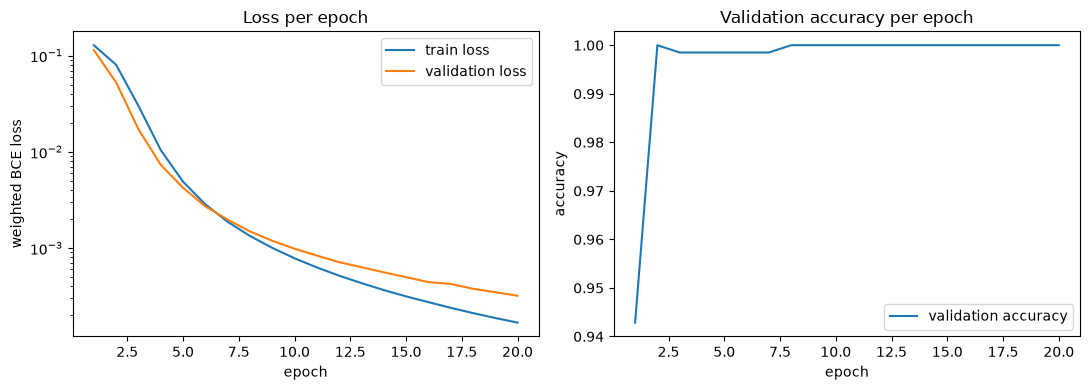

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, n_epochs + 1) #creates the x-axis values
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11,4)) #1 row 2 columns of plots, fig is the canvas, ax1 and ax2 are the individual plot areas, figsize sets the size
#draw 2 lines on the first panel, both against the same axes
ax1.plot(epochs, train_losses, label="train loss")
ax1.plot(epochs, val_losses, label="validation loss")
ax1.set_yscale("log") #changes scale of y-axis
ax1.set_xlabel("epoch") #labels for the panel
ax1.set_ylabel("weighted BCE loss")
ax1.set_title("Loss per epoch")
ax1.legend() #draws the label

ax2.plot(epochs, val_acc, label="validation accuracy")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy")
ax2.set_title("Validation accuracy per epoch")
ax2.legend()

plt.tight_layout() #adjust spacing between the panels
plt.savefig("figures/fig_cnn_curves.png", dpi=150) #saves to figures/ folder at 150 resolution

plt.show() #displays the fig in the notebook

## Pick the Best Epoch
Validation accuracy reaches 1.000 by epoch 3, and validation loss decreases every epoch until epoch 20 while staying close to the training loss, so there is no sign of overfitting. The lowest validation loss is at the last epoch, so we use the model after epoch 20.

## Result Analysis 
The CNN reaches 100% validation accuracy within a few epochs. Perfect scores are suspicious, so before touching the test set we check whether the result is actually trustworthy. There could be a trivial shortcut or data leakage helping the model guess correctly.

### Sanity check 1: Is the window average a shortcut?
Person windows had a higher average value than empty windows (see the data validity checks). We test whether that single number alone can predict the label.
Because 89.5% of validation windows are "person", always guessing "person" already gives 89.5% accuracy. We therefore use **balanced accuracy**: the average of "% of empty windows correct" and "% of person windows correct". Guessing gives 0.5.
**Result:** 0.55, close to guessing, so the average is useless and is not what the CNN relies on.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

means_train = X_train.reshape(len(X_train), -1).mean(axis=1).reshape(-1, 1)
means_val   = X_val.reshape(len(X_val), -1).mean(axis=1).reshape(-1, 1)

clf = LogisticRegression(class_weight="balanced")
clf.fit(means_train, y_train)
print("val accuracy using ONLY the window mean:", clf.score(means_val, y_val))
print("mean-only val balanced accuracy:", balanced_accuracy_score(y_val, clf.predict(means_val)))

val accuracy using ONLY the window mean: 0.36390977443609024
mean-only val balanced accuracy: 0.55


### Sanity check 2: Confusion matrix of the CNN
Shows exactly which windows the CNN got right or wrong, per class.
Rows = true class (empty, person), columns = predicted class.
**Result:** [[70, 0], [0, 595]], so every window is classified correctly. The 100% is not caused by the class imbalance.

In [14]:
model.eval()
with torch.no_grad():
    val_preds = (torch.sigmoid(model(X_val_t)) > 0.5).float().numpy()

print(confusion_matrix(y_val, val_preds, labels=[0, 1]))  # rows = true [empty, person], cols = predicted
print("CNN val balanced accuracy:", balanced_accuracy_score(y_val, val_preds))

[[ 70   0]
 [  0 595]]
CNN val balanced accuracy: 1.0


### Sanity check 3: Can one "motion" number solve the task?
A moving person makes the Wi-Fi signal fluctuate. For each window we compute one number: the typical change in signal between consecutive packets. Then we train a logistic regression on only that number.
**Result:** balanced accuracy 1.0. One number solves the task, so moving person vs. empty room is an easy problem in this dataset. The CNN's perfect score is legitimate, but the CNN is not needed for it.

In [15]:
def motion(X):
    return np.median(np.abs(np.diff(X, axis=1)), axis=(1, 2)).reshape(-1, 1)  # diff along time

clf_m = LogisticRegression(class_weight="balanced")
clf_m.fit(motion(X_train), y_train)
print("motion-only val balanced accuracy:", balanced_accuracy_score(y_val, clf_m.predict(motion(X_val))))

motion-only val balanced accuracy: 1.0


### Sanity check 4: Lab "Static" recordings (inconclusive)
We run the trained CNN on the Lab "Static" folder (a different room and Wi-Fi channel).
**Result:** 3009 of 3010 windows were predicted "person". In Stage 1 we found this folder's label is ambiguous: it could be an empty but noisier room, or a person sitting still. So this result cannot tell us whether the model generalises to other rooms.

In [16]:

X_lab, y_lab = make_windows(files["lab_static"], 0, T)
X_lab_t = torch.tensor(((X_lab - mean) / std)[:, None, :, :], dtype=torch.float32)

with torch.no_grad():
    lab_preds = (torch.sigmoid(model(X_lab_t)) > 0.5).float().numpy()

print("lab windows:", len(lab_preds),
      " predicted empty:", int((lab_preds == 0).sum()),
      " predicted person:", int((lab_preds == 1).sum()))

lab windows: 3010  predicted empty: 1  predicted person: 3009


### Sanity check 5: Shuffled labels (checking for bugs or data leakage)
We randomly shuffle the training labels so they no longer match the windows, then train a fresh CNN. If the pipeline is correct, it cannot learn anything real and should score about 0.5 (guessing).
**Result:** 0.50, so there is no bug or leakage. The perfect score comes from the real data.

In [17]:
rng = np.random.default_rng(0) # fixed seed so the result is reproducible
y_shuf_t = torch.tensor(rng.permutation(y_train), dtype=torch.float32) # same labels, random order
shuf_loader = DataLoader(TensorDataset(X_train_t, y_shuf_t), batch_size=32, shuffle=True)

shuf_model = SimpleCNN() # fresh model, so the real one is not overwritten
shuf_opt = optim.Adam(shuf_model.parameters(), lr=1e-3)
for epoch in range(3):
    shuf_model.train()
    for X_batch, y_batch in shuf_loader:
        shuf_opt.zero_grad()
        criterion(shuf_model(X_batch), y_batch).backward()
        shuf_opt.step()

shuf_model.eval()
with torch.no_grad():
    shuf_preds = (torch.sigmoid(shuf_model(X_val_t)) > 0.5).float().numpy()
print("shuffled-label CNN val balanced accuracy:", balanced_accuracy_score(y_val, shuf_preds))

shuffled-label CNN val balanced accuracy: 0.5785714285714286


## Evaluate once on test

In [ ]:
model.eval()
with torch.no_grad(): #not calling .backward() so dont track operations following gradient computation
    test_logits = model(X_test_t) #send entire test set through mdoel not via dataloader
    test_loss = criterion(test_logits, y_test_t).item() #feeding raw scores and true labels into loss function, .item() again pulls out one plain python float
    test_probs = torch.sigmoid(test_logits).numpy() #squashes the scores into a 0-1 range how probable that theres a person or not, then convert from tensor to numpy array
test_preds = (test_probs > 0.5).astype(float) #0.5 is the threshold giving final predictions
print("test loss:", test_loss)




## Report Metric

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

#.ravel() flattens to a list of 4 numbers -> unpacking into four variables
tn, fp, fn, tp = confusion_matrix(y_test, test_preds, labels=[0,1]).ravel() #builds same 2x2 grid, rows = true label, columns = predicted label
print(f"windows: {len(y_test)} (empty {int((y_test == 0).sum())}, person {int((y_test == 1).sum())})") #f" " lets you embed
print("confusion matrix (rows = true, columns = predicted):")
print(f"                 pred empty  pred person")
print(f"  true empty     {tn:10d}  {fp:11d}   <- FP = false alarms")
print(f"  true person    {fn:10d}  {tp:11d}   <- FN = missed people")

print(f"TPR (PERSON DETECTED)         ={recall_score(y_test, test_preds, pos_label=1):.3f}")
print(f"TNR (empty correctly empty) = {recall_score(y_test, test_preds, pos_label=0):.3f}")
print(f"precision                   = {precision_score(y_test, test_preds, zero_division=0):.3f}")
print(f"F1 (person)                 = {f1_score(y_test, test_preds, zero_division=0):.3f}")
print(f"balanced accuracy           = {balanced_accuracy_score(y_test, test_preds):.3f}")
print(f"test error (1 - balanced)   = {1 - balanced_accuracy_score(y_test, test_preds):.3f}")
print(f"ROC-AUC                     = {roc_auc_score(y_test, test_probs):.3f}")
